# Module project: teach a robot arm where to put its elbow

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-2-robot-arm-mdn.ipynb`, attached to this lesson and saved on your device with the course. It builds and runs the whole project. Open it in one click in Google Colab (free, nothing to install): [Open in Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/bishop-dl-2-deep-networks/files/project-2-robot-arm-mdn.ipynb). Or open the saved copy on your device with Jupyter or VS Code.
- **Finished code**: the `projects/robot-arm-mdn` folder in the course files, to check your work.
- **Data**: No download: the data comes from the arm simulator you write in `arm.py`.

In [ ]:
%pip install -q torch matplotlib

Section 6.5.1 opens with a robot arm (figure 6.16): given where you want the hand to go, which angles should the shoulder
and elbow take? It's a real problem in robotics, and it hides a trap. Most points can be reached two ways, elbow up or
elbow down. A network trained with squared error, the default loss for regression, will average the two answers, and
the average of two good arms is a bad arm.

In this project you build the book's example for real: a small arm simulator, a standard regression network that falls
into the trap, and a **mixture density network** that doesn't. The notebook attached above builds and runs the whole
project; the reference code is in the course files under `projects/robot-arm-mdn`.

## What you'll build

```mermaid
flowchart LR
    A[arm.py<br/>simulator: angles -> hand] --> B[20,000 random poses]
    B --> C[models.py<br/>squared-error network<br/>mixture density network]
    C --> D[train.py<br/>measure where<br/>the hand really ends up]
    D --> E[show.py<br/>draw the arms]
```

## Set up the project

```bash
mkdir robot-arm-mdn && cd robot-arm-mdn
python -m venv .venv && source .venv/bin/activate
pip install torch matplotlib
git init
```

```text
robot-arm-mdn/
    .gitignore
    README.md
    arm.py
    mdn.pt
    models.py
    regressor.pt
    requirements.txt
    show.py
    train.py
```

In [2]:
%%writefile requirements.txt
torch
matplotlib

Writing requirements.txt


In [3]:
%%writefile .gitignore
outputs/
__pycache__/
*.pt
.venv/

Writing .gitignore


## Step 1: the simulator

The **forward** direction is simple trigonometry: the elbow sits at the end of the first link, the hand at the end of the
second. We generate training data by picking random angles and computing where the hand lands, so the data is free and
perfectly labelled. The network has to learn the **inverse**: from hand position back to angles.

In [4]:
%%writefile arm.py
"""A two-link robot arm in a plane. Forward kinematics is easy: angles -> hand position.
The inverse (position -> angles) is the hard, useful direction, and it has two answers: elbow up or elbow down."""
import math
import torch

L1, L2 = 1.0, 0.7                     # link lengths


def forward(theta):
    """theta: (N, 2) shoulder and elbow angles in radians -> (N, 2) hand positions."""
    a, b = theta[:, 0], theta[:, 1]
    x = L1 * torch.cos(a) + L2 * torch.cos(a + b)
    y = L1 * torch.sin(a) + L2 * torch.sin(a + b)
    return torch.stack([x, y], 1)


def sample(n, seed=0):
    """Random reachable poses: shoulder in [-pi/2, pi/2], elbow bent either way by 0.3 to 2.6 radians."""
    g = torch.Generator().manual_seed(seed)
    shoulder = (torch.rand(n, generator=g) - 0.5) * math.pi
    bend = 0.3 + torch.rand(n, generator=g) * 2.3
    sign = torch.where(torch.rand(n, generator=g) < 0.5, -1.0, 1.0)
    theta = torch.stack([shoulder, sign * bend], 1)
    return forward(theta), theta       # inputs (positions), targets (angles)


if __name__ == "__main__":
    pos, theta = sample(5)
    for p, t in zip(pos, theta):
        print(f"angles ({t[0]:+.2f}, {t[1]:+.2f}) -> hand at ({p[0]:+.2f}, {p[1]:+.2f})")
    # the same hand position, reached the other way: mirror the arm across the line from shoulder to hand
    t = theta[:1]
    p = forward(t)[0]
    other = torch.tensor([[torch.atan2(p[1], p[0]) * 2 - t[0, 0], -t[0, 1]]])
    print(f"other solution for the first point: angles ({other[0, 0]:+.2f}, {other[0, 1]:+.2f}) -> "
          f"hand at ({forward(other)[0, 0]:+.2f}, {forward(other)[0, 1]:+.2f})")

Writing arm.py


In [5]:
!python arm.py

angles (-0.01, -1.76) -> hand at (+0.86, -0.70)
angles (+0.84, -1.43) -> hand at (+1.25, +0.36)
angles (-1.29, -2.36) -> hand at (-0.34, -0.62)
angles (-1.16, -1.35) -> hand at (-0.16, -1.33)
angles (-0.60, -1.75) -> hand at (+0.33, -1.06)
other solution for the first point: angles (-1.35, +1.76) -> hand at (+0.86, -0.70)


The last line shows the trap: two different pairs of angles, (−0.01, −1.76) and (−1.35, +1.76), put the hand at
exactly the same point. In the training data, both kinds appear.

## Step 2: two networks

Both share the same body: two hidden layers of 128 `tanh` units.

- The **regressor** outputs two angles and is trained with squared error. Section 6.4.1 shows that squared error is the
  negative log likelihood of a **single Gaussian** around the prediction. When the data really has two clusters of
  answers, the best single Gaussian sits between them.
- The **mixture density network** outputs, for each input, the parameters of a mixture of K = 3 Gaussians: mixing
  weights (through a softmax, so they add to 1), means, and widths (through `exp`, so they're positive). It's trained by
  the negative log likelihood of that mixture, equation 6.43. To get one answer from it, we take the mean of the most
  probable component.

In [6]:
%%writefile models.py
"""Two networks for the inverse problem (Bishop, sections 6.4 and 6.5)."""
import math
import torch
from torch import nn


def body(hidden=128):
    return nn.Sequential(nn.Linear(2, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh())


class Regressor(nn.Module):
    """Predicts the angles directly, trained with squared error = a Gaussian with ONE peak (section 6.4.1)."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(body(), nn.Linear(128, 2))

    def loss(self, x, t):
        return ((self(x) - t) ** 2).sum(1).mean()

    def forward(self, x):
        return self.net(x)


class MDN(nn.Module):
    """Mixture density network (section 6.5): the network outputs a whole distribution over the angles,
    a mixture of K Gaussians, each with its own weight pi_k, mean mu_k and width sigma_k."""
    def __init__(self, K=3):
        super().__init__()
        self.K = K
        self.body = body()
        self.head = nn.Linear(128, K * (1 + 2 + 1))          # per component: logit, 2 means, log sigma

    def params(self, x):
        out = self.head(self.body(x))
        logits, mu, log_sigma = out[:, :self.K], out[:, self.K:3 * self.K], out[:, 3 * self.K:]
        return torch.log_softmax(logits, 1), mu.reshape(-1, self.K, 2), log_sigma

    def loss(self, x, t):
        """Negative log likelihood of the mixture (equation 6.43), computed with logsumexp."""
        log_pi, mu, log_sigma = self.params(x)
        d2 = ((t[:, None, :] - mu) ** 2).sum(2)                      # (N, K)
        log_normal = -d2 / (2 * torch.exp(2 * log_sigma)) - 2 * log_sigma - math.log(2 * math.pi)
        return -torch.logsumexp(log_pi + log_normal, 1).mean()

    def forward(self, x):
        """The mean of the most probable component: one good answer, not an average of two."""
        log_pi, mu, _ = self.params(x)
        return mu[torch.arange(len(x)), log_pi.argmax(1)]

Writing models.py


The loss uses `torch.logsumexp` for the same reason as in part 1's projects: adding probabilities that may be tiny,
safely, in log space.

## Step 3: train and measure the right thing

What matters to a robot isn't the error in the angles, it's **where the hand ends up**. So `reach_error` puts each
network's angles through the simulator and measures the distance to the target.

In [7]:
%%writefile train.py
"""Train both networks on 20,000 random poses and measure how close each one's answer puts the hand."""
import torch
from arm import forward, sample
from models import Regressor, MDN

torch.manual_seed(0)
x_tr, t_tr = sample(20000, seed=0)
x_te, t_te = sample(2000, seed=1)


def fit(model, steps=4000):
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for step in range(steps):
        idx = torch.randint(0, len(x_tr), (256,))
        loss = model.loss(x_tr[idx], t_tr[idx])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model


def reach_error(model):
    """Distance between where we asked the hand to go and where the predicted angles really put it."""
    with torch.no_grad():
        return (forward(model(x_te)) - x_te).norm(dim=1)


for name, model in [("squared-error network", Regressor()), ("mixture density network", MDN())]:
    fit(model)
    err = reach_error(model)
    print(f"{name:24s} median miss {err.median():.3f}, worst 10% miss more than {err.quantile(0.9):.3f} "
          f"(arm length {1.7})")
    torch.save(model.state_dict(), "mdn.pt" if isinstance(model, MDN) else "regressor.pt")

Writing train.py


In [8]:
!python train.py

squared-error network    median miss 0.120, worst 10% miss more than 0.801 (arm length 1.7)


mixture density network  median miss 0.003, worst 10% miss more than 0.012 (arm length 1.7)


The squared-error network misses by 0.12 in the typical case and by more than 0.8 for one target in ten, on an arm whose
full reach is 1.7. The mixture density network misses by 0.003. Same body, same data, same optimizer: only the
**assumption about the shape of the answer** changed.

## Step 4: look at the arms

In [9]:
%%writefile show.py
"""Draw the arms each network proposes for a few target points."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from arm import L1, forward
from models import Regressor, MDN

reg, mdn = Regressor(), MDN()
reg.load_state_dict(torch.load("regressor.pt")); mdn.load_state_dict(torch.load("mdn.pt"))
targets = torch.tensor([[0.9, -0.6], [1.2, 0.5], [0.3, 1.1]])


def draw(ax, theta, **style):
    a, b = theta
    elbow = (L1 * torch.cos(a), L1 * torch.sin(a))
    hand = forward(theta[None])[0]
    ax.plot([0, elbow[0], hand[0]], [0, elbow[1], hand[1]], "-o", ms=3, **style)


Path("outputs").mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
with torch.no_grad():
    log_pi, mu, _ = mdn.params(targets)
    for i, ax in enumerate(axes):
        for k in range(mdn.K):
            w = log_pi[i, k].exp().item()
            if w > 0.05:
                draw(ax, mu[i, k], color="C0", alpha=0.3 + 0.7 * w, label=f"MDN component, weight {w:.2f}")
        draw(ax, reg(targets[i:i + 1])[0], color="C3", label="squared-error network")
        ax.plot(*targets[i], "k*", ms=14, label="target")
        ax.set_aspect("equal"); ax.set_xlim(-0.6, 1.8); ax.set_ylim(-1.3, 1.5); ax.legend(fontsize=7, loc="best")
        print(f"target ({targets[i, 0]:+.1f}, {targets[i, 1]:+.1f}): MDN weights "
              + ", ".join(f"{p:.2f}" for p in log_pi[i].exp()))
fig.tight_layout(); fig.savefig("outputs/arms.png", dpi=110)
print("saved outputs/arms.png")

Writing show.py


In [10]:
!python show.py

target (+0.9, -0.6): MDN weights 0.46, 0.04, 0.50
target (+1.2, +0.5): MDN weights 0.52, 0.47, 0.00
target (+0.3, +1.1): MDN weights 0.97, 0.03, 0.00


saved outputs/arms.png


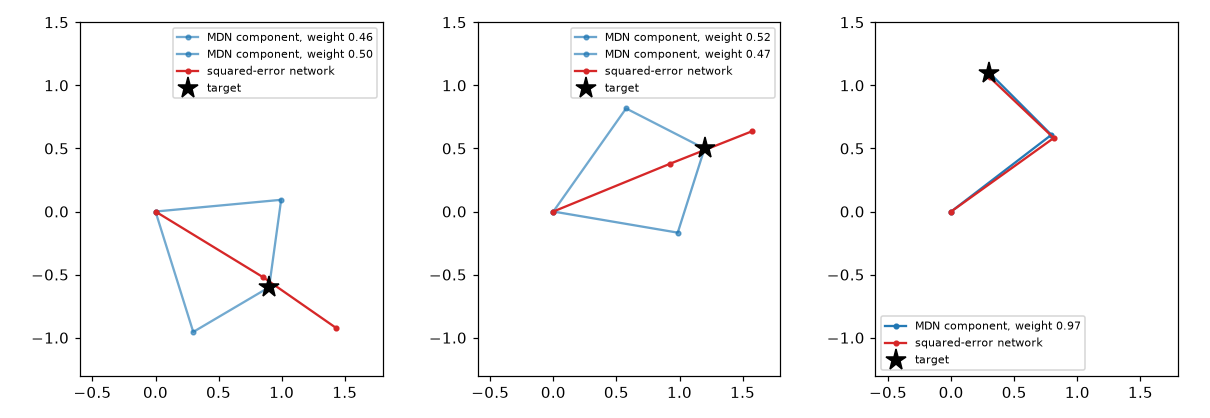

In [11]:
from IPython.display import Image
Image('outputs/arms.png')

In the first two panels the MDN puts almost equal weight on two components, and they're the two real solutions, elbow up
and elbow down. The squared-error network averages them: the elbow angle comes out near zero, a **straight arm** that
overshoots the target. In the third panel only one solution is in the range of poses we trained on, the MDN puts 97% of
its weight on it, and the two networks agree.

This is section 6.5's lesson in one picture: when the conditional distribution `p(t | x)` has several peaks, predict the
distribution, not a single number.

## Step 5: write the README and publish

In [12]:
%%writefile README.md
# Robot arm inverse kinematics with a mixture density network

Learns which joint angles put a two-link robot arm's hand at a given point. The problem has two answers for most
points (elbow up or elbow down), so a network trained with squared error averages them into an arm that misses. A
mixture density network (PyTorch) learns the whole distribution of answers instead.

![arms](outputs/arms.png)

## Results (2,000 new target points; arm reach 1.7)

| model | median miss | 90th percentile miss |
|---|---|---|
| network trained with squared error | 0.120 | 0.801 |
| mixture density network, 3 components | **0.003** | **0.012** |

## Run it

```bash
pip install -r requirements.txt
python train.py    # train both networks (about a minute on a laptop)
python show.py     # draw their arms for three targets
```

## What I learned

- Squared error assumes one Gaussian peak; when the true answer has two, the network predicts their average, which can
  be no answer at all.
- An MDN outputs mixing weights, means and widths, and is trained by the mixture's negative log likelihood.
- Measure what matters: here, where the hand actually ends up, not the error in the angles.

Based on section 6.5 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Robot arm inverse kinematics with a mixture density network"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/robot-arm-mdn.git
git push -u origin main
```

## Make it yours

- **Choose the solution you want.** A real robot may prefer the elbow-up solution, or the one closest to its current
  pose. Instead of the most probable component, pick the component whose mean is closest to a given current pose.
- **Animate it.** Move the target along a circle and draw the arm frame by frame with `matplotlib.animation`. What
  happens when the MDN switches between components?
- **K = 1 and K = 2.** With K = 1, the MDN is a regressor with a learned width. Does it fail like the squared-error
  network? Is K = 2 enough?
- **Three links.** Add a third link. Now most points have infinitely many solutions. What does the MDN learn?

## On your CV

> **Robot arm inverse kinematics** (PyTorch): mixture density network that learns both elbow configurations of a
> two-link arm; reduced the median positioning error from 0.12 to 0.003 (arm reach 1.7) compared with a standard
> squared-error network. github.com/YOUR-USERNAME/robot-arm-mdn

## Check yourself

- [ ] You can explain, with the picture, why the squared-error network draws a straight arm.
- [ ] You can write the MDN's loss on paper.
- [ ] You measured the error in hand position, not in angles.